**INSIGHTS ON DATA**


*   **Dataset Source**: The dataset used in this project is the New Plant Diseases Dataset available on Kaggle.
*   **Dataset Description:** he original dataset comprises over 87,000 RGB images of both healthy and diseased crop leaves, categorized into 38 distinct classes. The dataset is organized into an 80/20 split for training and validation purposes, with the directory structure preserved. An additional directory containing 33 test images was later created specifically for prediction tasks.

*   **Data Subset Selection:** Due to the large size of the complete dataset, a subset was selected focusing only on apple and corn plant classes. For each of these two classes, 500 images were used for training and 100 images were reserved for validation.
*   **Test Set for Visualization:** A separate test directory was created, containing 10 images pertaining only to the selected apple and corn classes. These images were utilized primarily for result visualization, while the model’s performance and accuracy were evaluated using the 100 validation images.




In [ ]:
!pip install tensorflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 644.9/644.9 MB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.5/57.5 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.5/24.5 MB 83.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 96.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.1/5.1 MB 93.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 123.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 224.5/224.5 kB 18.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/72.5 kB 6.4 MB/s eta 0:00:00


In [ ]:
!pip install scikit-image

In [ ]:
!pip install opencv-python-headless

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.0/50.0 MB 27.3 MB/s eta 0:00:00


In [ ]:
import kagglehub

path = kagglehub.dataset_download("vipoooool/new-plant-diseases-dataset")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/new-plant-diseases-dataset


Checking the directory structure for the dataset as it was a bit confusing

In [ ]:
import os

In [ ]:
data_dir = '/kaggle/input/new-plant-diseases-dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)'
classes = os.listdir(data_dir)
classes

['valid', 'train']

# **Plant Disease Classification using VGG16 and SVM**

 This code implements a plant disease classification system using:
 - VGG16 (pre-trained on ImageNet) for feature extraction
 - SVM (Support Vector Machine) for classification
 - Data augmentation to increase training data diversity

 **Key Components:**

 1. **Data Preparation**
    - Filters dataset to only include Apple and Corn classes
    - Creates balanced subsets with specified number of samples per class
    - Handles both training and validation sets

 2. **Data Augmentation**
    - Implements multiple augmentation techniques:
      - Random flips (horizontal/vertical)
      - Rotation (90 degrees)
      - Brightness adjustment
      - Gaussian noise
      - Blurring
      - Random cropping
      - Color shifting
      - Generates multiple augmented versions per original image

 3. **Feature Extraction**
    - Uses VGG16 (without top layers) as feature extractor
    - Extracts 512-dimensional features via Global Average Pooling
    - Supports both CPU and GPU processing

 4. **Classification**
    - Implements SVM with RBF kernel
    - Supports both CPU (scikit-learn) and GPU (cuML) implementations
    - Includes hyperparameter tuning (for CPU version)

 5. **Evaluation**
    - Accuracy score
    - Classification report
    - Confusion matrix visualization

 **GPU Acceleration Support:**
 - Attempts to use cuML for GPU-accelerated SVM when available
 - Uses TensorFlow GPU support for feature extraction when available
 - Falls back to CPU implementations when GPU not available

  ***Key Parameters:***
 - train_samples = 500  # Samples per class in training
 - validation_samples = 100  # Samples per class in validation
 - augmentations_per_image = 3  # Augmented versions per original image
 - batch_size = 32  # For feature extraction
 - C_value = 10  # SVM regularization parameter
 - gamma_value = 'scale'  # SVM kernel coefficient

  ***Outputs:***
 - augmentation_samples.png - Visual examples of augmentations
 - confusion_matrix.png - Visual representation of model performance
 - Model evaluation metrics printed to console

GPU not available for cuML: No module named 'cupy'
Using CPU for SVM training.
Checking TensorFlow GPU availability...
TensorFlow version: 2.19.0
GPU devices: []
TensorFlow will run on CPU.
Found 8 disease classes for Apple and Corn:
- Corn_(maize)___Northern_Leaf_Blight
- Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
- Apple___Apple_scab
- Apple___Black_rot
- Apple___Cedar_apple_rust
- Apple___healthy
- Corn_(maize)___Common_rust_
- Corn_(maize)___healthy
Processed class 'Corn_(maize)___Northern_Leaf_Blight' with 500 images.
Processed class 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot' with 500 images.
Processed class 'Apple___Apple_scab' with 500 images.
Processed class 'Apple___Black_rot' with 500 images.
Processed class 'Apple___Cedar_apple_rust' with 500 images.
Processed class 'Apple___healthy' with 500 images.
Processed class 'Corn_(maize)___Common_rust_' with 500 images.
Processed class 'Corn_(maize)___healthy' with 500 images.
Found 8 disease classes for Apple and 

Augmenting classes: 100%|██████████| 8/8 [00:27<00:00,  3.40s/it]


Augmentation completed
Loading data from /content/reduced_dataset/valid...


100%|██████████| 8/8 [00:00<00:00, 18.69it/s]


Loading data from /content/augmented_dataset/train...


100%|██████████| 8/8 [00:10<00:00,  1.28s/it]


Loaded 16000 training images (including augmentations) with 8 classes
Loaded 800 validation images
Classes: ['Apple___Apple_scab' 'Apple___Black_rot' 'Apple___Cedar_apple_rust'
 'Apple___healthy' 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot'
 'Corn_(maize)___Common_rust_' 'Corn_(maize)___Northern_Leaf_Blight'
 'Corn_(maize)___healthy']
Creating VGG16 feature extractor...
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
VGG16 feature extractor created: 512 dimensions

Extracting VGG features...
Extracting VGG features using: /CPU:0


Extracting VGG features: 100%|██████████| 500/500 [59:00<00:00,  7.08s/it]


VGG feature extraction completed in 3554.12 seconds
Feature dimensions: 512
Extracting VGG features using: /CPU:0


Extracting VGG features: 100%|██████████| 25/25 [02:57<00:00,  7.09s/it]


VGG feature extraction completed in 178.14 seconds
Feature dimensions: 512

Scaling features...
Optimizing SVM hyperparameters...
Fitting 3 folds for each of 16 candidates, totalling 48 fits
Best parameters: {'C': 20, 'gamma': 'scale'}
Best cross-validation score: 0.9517

Training SVM model...
SVM training and prediction completed in 96.08 seconds

Validation Accuracy: 97.88%

Classification Report:
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       1.00      0.96      0.98       100
                                 Apple___Black_rot       0.96      0.99      0.98       100
                          Apple___Cedar_apple_rust       1.00      1.00      1.00       100
                                   Apple___healthy       0.98      0.98      0.98       100
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.98      0.94      0.96       100
                       Corn_(maize)___Common

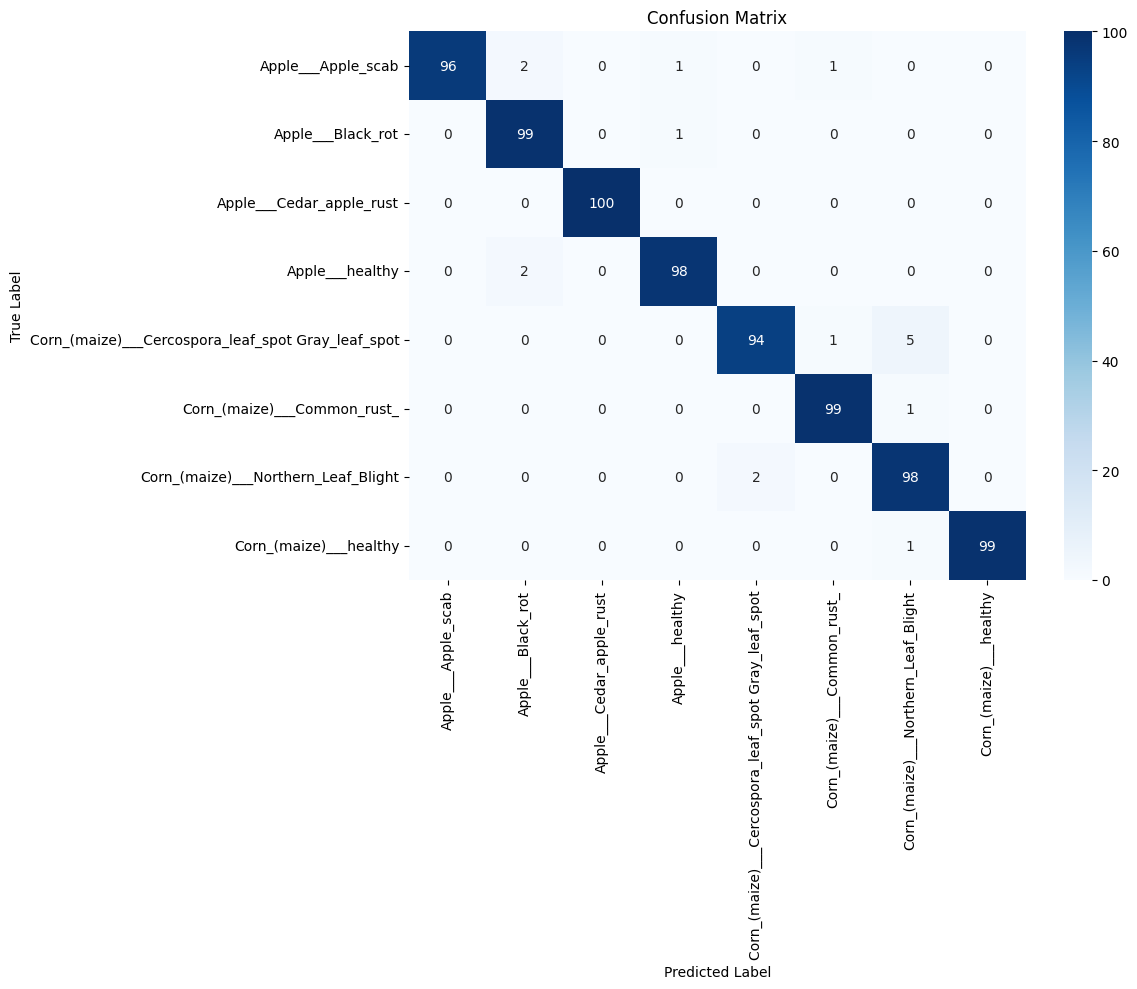

In [ ]:
import os
import cv2
import numpy as np
import random
import shutil
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder, StandardScaler
import seaborn as sns
import time
from tqdm import tqdm
import joblib
import tensorflow as tf

# Try to import GPU libraries
try:
    import cupy as cp  # For GPU acceleration
    from cuml.svm import SVC as cuSVC
    from cuml.preprocessing import StandardScaler as cuStandardScaler
    # Test GPU functionality
    test_array = cp.array([1, 2, 3])
    GPU_AVAILABLE = True
    print("cuML is available! Using GPU acceleration for SVM.")
except Exception as e:
    GPU_AVAILABLE = False
    print(f"GPU not available for cuML: {e}")
    print("Using CPU for SVM training.")

# Check for TensorFlow GPU
print("Checking TensorFlow GPU availability...")
print(f"TensorFlow version: {tf.__version__}")
print(f"GPU devices: {tf.config.list_physical_devices('GPU')}")
TF_GPU = len(tf.config.list_physical_devices('GPU')) > 0
if TF_GPU:
    print("TensorFlow with GPU support available!")
else:
    print("TensorFlow will run on CPU.")

# Set random seed for reproducibility
random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

# Dataset paths
base_path = '/kaggle/input/new-plant-diseases-dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)'
train_path = os.path.join(base_path, "train")
validation_path = os.path.join(base_path, "valid")
output_train_path = "/content/reduced_dataset/train"
output_validation_path = "/content/reduced_dataset/valid"
augmented_train_path = "/content/augmented_dataset/train"

# Filter only Apple and Corn classes
target_plants = ['Apple', 'Corn']

def create_filtered_subset(input_path, output_path, samples_per_class=None):
    """Create a subset containing only Apple and Corn classes"""
    if not os.path.exists(output_path):
        os.makedirs(output_path)

    # Get all class directories
    class_dirs = [d for d in os.listdir(input_path) if os.path.isdir(os.path.join(input_path, d))]

    # Filter class directories containing 'Apple' or 'Corn'
    filtered_dirs = [d for d in class_dirs if any(plant in d for plant in target_plants)]

    print(f"Found {len(filtered_dirs)} disease classes for Apple and Corn:")
    for d in filtered_dirs:
        print(f"- {d}")

    # Copy files for each filtered class
    for class_name in filtered_dirs:
        class_dir = os.path.join(input_path, class_name)
        images = os.listdir(class_dir)

        # If samples_per_class is specified, take a random subset
        if samples_per_class and len(images) > samples_per_class:
            random.shuffle(images)
            selected_images = images[:samples_per_class]
        else:
            selected_images = images

        # Create output directory and copy files
        class_output_dir = os.path.join(output_path, class_name)
        os.makedirs(class_output_dir, exist_ok=True)

        for image in selected_images:
            src = os.path.join(class_dir, image)
            dst = os.path.join(class_output_dir, image)
            shutil.copy(src, dst)

        print(f"Processed class '{class_name}' with {len(selected_images)} images.")

# Data augmentation functions
def apply_augmentation(img):
    """Apply a random augmentation to an image"""
    augmentations = [
        lambda x: x,  # identity
        lambda x: cv2.flip(x, 1),  # horizontal flip
        lambda x: cv2.flip(x, 0),  # vertical flip
        lambda x: cv2.rotate(x, cv2.ROTATE_90_CLOCKWISE),  # 90 degree rotation
        lambda x: adjust_brightness(x, gamma=random.uniform(0.8, 1.2)),  # brightness
        lambda x: apply_gaussian_noise(x, mean=0, sigma=10),  # add noise
        lambda x: apply_blur(x, kernel_size=5),  # blur
        lambda x: random_crop_and_resize(x, crop_percent=0.8),  # random crop
        lambda x: color_shift(x, hue_shift=random.uniform(-10, 10)),  # color shift
    ]
    # Apply 1-3 random augmentations
    num_augs = random.randint(1, 3)
    chosen_augs = random.sample(augmentations, num_augs)

    result = img.copy()
    for aug_func in chosen_augs:
        result = aug_func(result)
    return result

def adjust_brightness(img, gamma=1.0):
    """Adjust image brightness using gamma correction"""
    inv_gamma = 1.0 / gamma
    table = np.array([((i / 255.0) ** inv_gamma) * 255 for i in range(256)]).astype("uint8")
    return cv2.LUT(img, table)

def apply_gaussian_noise(img, mean=0, sigma=10):
    """Add Gaussian noise to image"""
    noise = np.random.normal(mean, sigma, img.shape).astype(np.int16)
    noisy_img = np.clip(img.astype(np.int16) + noise, 0, 255).astype(np.uint8)
    return noisy_img

def apply_blur(img, kernel_size=5):
    """Apply Gaussian blur to image"""
    return cv2.GaussianBlur(img, (kernel_size, kernel_size), 0)

def random_crop_and_resize(img, crop_percent=0.8):
    """Randomly crop image and resize back to original size"""
    height, width = img.shape[:2]
    crop_h = int(height * crop_percent)
    crop_w = int(width * crop_percent)

    # Random crop coordinates
    start_h = random.randint(0, height - crop_h)
    start_w = random.randint(0, width - crop_w)

    # Crop the image
    cropped = img[start_h:start_h+crop_h, start_w:start_w+crop_w]

    # Resize back to original dimensions
    return cv2.resize(cropped, (width, height))

def color_shift(img, hue_shift=0):
    """Shift the hue of an image"""
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV).astype(np.int16)
    hsv[:,:,0] = (hsv[:,:,0] + hue_shift) % 180
    hsv = np.clip(hsv, 0, 255).astype(np.uint8)
    return cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)

def create_augmented_dataset(input_path, output_path, augmentations_per_image=2):
    """Create an augmented dataset"""
    if not os.path.exists(output_path):
        os.makedirs(output_path)

    # Get all class directories
    class_dirs = [d for d in os.listdir(input_path) if os.path.isdir(os.path.join(input_path, d))]

    print(f"Creating augmented dataset with {augmentations_per_image} augmentations per image")

    for class_name in tqdm(class_dirs, desc="Augmenting classes"):
        class_dir = os.path.join(input_path, class_name)
        class_output_dir = os.path.join(output_path, class_name)
        os.makedirs(class_output_dir, exist_ok=True)

        # First, copy original images
        for img_file in os.listdir(class_dir):
            src = os.path.join(class_dir, img_file)
            dst = os.path.join(class_output_dir, img_file)
            shutil.copy(src, dst)

            # Now create augmentations
            img = cv2.imread(src)
            if img is not None:
                for i in range(augmentations_per_image):
                    aug_img = apply_augmentation(img)
                    aug_filename = f"aug_{i}_{img_file}"
                    aug_path = os.path.join(class_output_dir, aug_filename)
                    cv2.imwrite(aug_path, aug_img)

    print("Augmentation completed")

# Optimized data loading
def load_data(data_dir):
    images = []
    labels = []
    image_paths = []
    label_encoder = LabelEncoder()

    print(f"Loading data from {data_dir}...")
    class_folders = sorted(os.listdir(data_dir))

    for class_folder in tqdm(class_folders):
        class_path = os.path.join(data_dir, class_folder)
        if os.path.isdir(class_path):
            for img_file in os.listdir(class_path):
                img_path = os.path.join(class_path, img_file)
                img = cv2.imread(img_path)
                if img is not None:
                    images.append(img)
                    labels.append(class_folder)
                    image_paths.append(img_path)

    labels_encoded = label_encoder.fit_transform(labels)
    return np.array(images), labels_encoded, label_encoder, image_paths

# VGG16 Feature Extractor
def create_vgg_feature_extractor():
    """Create a VGG16 model for feature extraction"""
    print("Creating VGG16 feature extractor...")

    # Load VGG16 without classification layers and pre-trained on ImageNet
    base_model = tf.keras.applications.VGG16(
        weights='imagenet',
        include_top=False,
        input_shape=(224, 224, 3)
    )

    # Freeze the base model layers
    for layer in base_model.layers:
        layer.trainable = False

    # Create a feature extraction model
    feature_extractor = tf.keras.Sequential([
        base_model,
        tf.keras.layers.GlobalAveragePooling2D()
    ])

    print(f"VGG16 feature extractor created: {feature_extractor.output_shape[1]} dimensions")
    return feature_extractor

def preprocess_for_vgg(images):
    """Preprocess images for VGG16"""
    # Resize to VGG input size
    resized_images = np.array([cv2.resize(img, (224, 224)) for img in images])

    # Convert from BGR (OpenCV) to RGB (TensorFlow)
    rgb_images = resized_images[..., ::-1]

    # Preprocess input for VGG16
    preprocessed = tf.keras.applications.vgg16.preprocess_input(rgb_images)
    return preprocessed

def extract_vgg_features(images, feature_extractor, batch_size=32, use_gpu=True):
    """Extract VGG16 features in batches"""
    start_time = time.time()

    # Preprocess all images
    preprocessed_images = preprocess_for_vgg(images)

    # Check for GPU use
    device = '/GPU:0' if use_gpu and TF_GPU else '/CPU:0'
    print(f"Extracting VGG features using: {device}")

    # Extract features in batches to prevent memory overflow
    features_list = []
    with tf.device(device):
        num_batches = int(np.ceil(len(preprocessed_images) / batch_size))
        for i in tqdm(range(num_batches), desc="Extracting VGG features"):
            start_idx = i * batch_size
            end_idx = min((i + 1) * batch_size, len(preprocessed_images))
            batch = preprocessed_images[start_idx:end_idx]

            # Extract features for the batch
            batch_features = feature_extractor.predict(batch, verbose=0)
            features_list.append(batch_features)

    # Combine all batches
    features = np.vstack(features_list)

    end_time = time.time()
    print(f"VGG feature extraction completed in {end_time - start_time:.2f} seconds")
    print(f"Feature dimensions: {features.shape[1]}")

    # Convert to GPU array if needed for SVM
    if use_gpu and GPU_AVAILABLE:
        try:
            features_gpu = cp.array(features)
            return features_gpu
        except Exception as e:
            print(f"Error converting to GPU array: {e}")
            print("Falling back to CPU")

    return features

# Create filtered subsets
train_samples = 500
validation_samples = 100
create_filtered_subset(train_path, output_train_path, train_samples)
create_filtered_subset(validation_path, output_validation_path, validation_samples)

# Create augmented dataset
create_augmented_dataset(output_train_path, augmented_train_path, augmentations_per_image=3)

# Load original data for validation
X_val, y_val, label_encoder_val, val_paths = load_data(output_validation_path)

# Load augmented data for training
X_train, y_train, label_encoder, train_paths = load_data(augmented_train_path)

# Print class information
class_names = label_encoder.classes_
print(f"Loaded {len(X_train)} training images (including augmentations) with {len(class_names)} classes")
print(f"Loaded {len(X_val)} validation images")
print("Classes:", class_names)

# Save sample augmented images for inspection
def save_sample_augmentations():
    """Save some sample augmentations for visualization"""
    plt.figure(figsize=(15, 10))
    samples_per_class = {}
    sample_idx = 0

    for class_name in class_names:
        class_indices = [i for i, path in enumerate(train_paths) if class_name in path]
        if len(class_indices) > 0:
            # Get original and augmented samples
            orig_indices = [i for i in class_indices if 'aug_' not in os.path.basename(train_paths[i])]
            aug_indices = [i for i in class_indices if 'aug_' in os.path.basename(train_paths[i])]

            if len(orig_indices) > 0 and len(aug_indices) > 0:
                # Get one original image
                orig_idx = orig_indices[0]

                plt.subplot(len(class_names), 4, sample_idx*4 + 1)
                plt.imshow(cv2.cvtColor(X_train[orig_idx], cv2.COLOR_BGR2RGB))
                plt.title(f"{class_name}\nOriginal")
                plt.axis('off')

                # Get up to 3 augmentations
                for j, aug_idx in enumerate(aug_indices[:3]):
                    plt.subplot(len(class_names), 4, sample_idx*4 + j + 2)
                    plt.imshow(cv2.cvtColor(X_train[aug_idx], cv2.COLOR_BGR2RGB))
                    plt.title(f"Augmentation {j+1}")
                    plt.axis('off')

                sample_idx += 1

    plt.tight_layout()
    plt.savefig('augmentation_samples.png')
    plt.close()

# Save augmentation samples
save_sample_augmentations()

# Create VGG feature extractor
vgg_feature_extractor = create_vgg_feature_extractor()

# Extract VGG features using GPU if available
print("\nExtracting VGG features...")
X_train_features = extract_vgg_features(X_train, vgg_feature_extractor, use_gpu=TF_GPU)
X_val_features = extract_vgg_features(X_val, vgg_feature_extractor, use_gpu=TF_GPU)

# Scale features (important for SVM)
print("\nScaling features...")
if GPU_AVAILABLE:
    try:
        # GPU-accelerated scaling
        scaler = cuStandardScaler()
        X_train_scaled = scaler.fit_transform(X_train_features)
        X_val_scaled = scaler.transform(X_val_features)
        # Convert y to GPU arrays
        y_train_gpu = cp.array(y_train)
    except Exception as e:
        print(f"Error with GPU scaling: {e}")
        print("Falling back to CPU scaling")
        GPU_AVAILABLE = False

if not GPU_AVAILABLE:
    # CPU scaling
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_features)
    X_val_scaled = scaler.transform(X_val_features)

# Cross-validation to find optimal hyperparameters
from sklearn.model_selection import GridSearchCV

def optimize_hyperparameters(X, y):
    """Find optimal hyperparameters using grid search"""
    print("Optimizing SVM hyperparameters...")
    param_grid = {
        'C': [1, 5, 10, 20],
        'gamma': ['scale', 'auto', 0.01, 0.1]
    }

    grid_search = GridSearchCV(
        SVC(kernel='rbf', probability=True, random_state=42),
        param_grid,
        cv=3,
        scoring='accuracy',
        n_jobs=-1,
        verbose=1
    )

    grid_search.fit(X, y)

    print(f"Best parameters: {grid_search.best_params_}")
    print(f"Best cross-validation score: {grid_search.best_score_:.4f}")

    return grid_search.best_params_

# Run hyperparameter optimization if not using GPU
if not GPU_AVAILABLE:
    # Get a subset of the data for faster hyperparameter tuning
    sample_size = min(3000, len(X_train_scaled))
    indices = np.random.choice(len(X_train_scaled), sample_size, replace=False)
    best_params = optimize_hyperparameters(X_train_scaled[indices], y_train[indices])
    C_value = best_params['C']
    gamma_value = best_params['gamma']
else:
    # Use default values for GPU
    C_value = 10
    gamma_value = 'scale'

# Train SVM with optimized parameters
print("\nTraining SVM model...")
start_time = time.time()

if GPU_AVAILABLE:
    try:
        # GPU-accelerated SVM
        svm = cuSVC(C=C_value, kernel='rbf', gamma=gamma_value, probability=True)
        svm.fit(X_train_scaled, y_train_gpu)

        # For prediction, keep on GPU
        y_pred_gpu = svm.predict(X_val_scaled)
        # Move results back to CPU for evaluation
        y_pred = cp.asnumpy(y_pred_gpu)
    except Exception as e:
        print(f"Error with GPU SVM: {e}")
        print("Falling back to CPU SVM")
        GPU_AVAILABLE = False

if not GPU_AVAILABLE:
    # CPU SVM
    svm = SVC(C=C_value, kernel='rbf', gamma=gamma_value, probability=True, random_state=42)
    svm.fit(X_train_scaled, y_train)
    y_pred = svm.predict(X_val_scaled)

end_time = time.time()
print(f"SVM training and prediction completed in {end_time - start_time:.2f} seconds")

# Evaluate model
accuracy = accuracy_score(y_val, y_pred)
print(f"\nValidation Accuracy: {accuracy * 100:.2f}%")
print("\nClassification Report:")
report = classification_report(y_val, y_pred, target_names=class_names)
print(report)

# Visualize confusion matrix
plt.figure(figsize=(12, 10))
cm = confusion_matrix(y_val, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig('confusion_matrix.png')
plt.show()


In [ ]:
def save_model(svm_model, scaler_model, label_encoder_model, vgg_model):
    """Save model and related components for future use"""
    os.makedirs('model', exist_ok=True)

    # Save SVM model
    if GPU_AVAILABLE:
        # For GPU models, we need to transfer to CPU first
        try:
            print("Converting GPU model to CPU for saving...")
            svm_cpu = SVC(C=C_value, kernel='rbf', gamma=gamma_value, probability=True)
            svm_cpu.fit(cp.asnumpy(X_train_scaled), cp.asnumpy(y_train_gpu))
            joblib.dump(svm_cpu, 'model/svm_model.pkl')
        except Exception as e:
            print(f"Error saving GPU model: {e}")
    else:
        joblib.dump(svm_model, 'model/svm_model.pkl')

    # Save scaler
    if GPU_AVAILABLE:
        # Convert GPU scaler to CPU
        try:
            scaler_cpu = StandardScaler()
            # We need to fit the CPU scaler with the same data
            scaler_cpu.fit(cp.asnumpy(X_train_features))
            joblib.dump(scaler_cpu, 'model/scaler.pkl')
        except Exception as e:
            print(f"Error saving GPU scaler: {e}")
    else:
        joblib.dump(scaler_model, 'model/scaler.pkl')

    # Save label encoder
    joblib.dump(label_encoder_model, 'model/label_encoder.pkl')

    # Save VGG feature extractor - add .keras extension to the filename
    vgg_model.save('model/vgg_feature_extractor.keras')

    print("Model and components saved to 'model/' directory")

# Add function to load model and make predictions on new images
def load_model_and_predict(image_path):
    """Load the saved model and predict disease for a new image"""
    # Load components
    svm_model = joblib.load('model/svm_model.pkl')
    scaler = joblib.load('model/scaler.pkl')
    label_encoder = joblib.load('model/label_encoder.pkl')
    vgg_feature_extractor = tf.keras.models.load_model('model/vgg_feature_extractor.keras')

    # Load and preprocess image
    img = cv2.imread(image_path)
    if img is None:
        return "Error: Could not load image"

    # Extract VGG features
    img_array = np.array([img])
    preprocessed = preprocess_for_vgg(img_array)
    features = vgg_feature_extractor.predict(preprocessed)

    # Scale features and predict
    features_scaled = scaler.transform(features)
    prediction = svm_model.predict(features_scaled)
    predicted_class = label_encoder.inverse_transform(prediction)[0]

    # Get probability
    probability = svm_model.predict_proba(features_scaled)[0][prediction[0]]

    return predicted_class, probability

# Save model and components
save_model(svm, scaler, label_encoder, vgg_feature_extractor)

# Print a usage example for prediction
print("\nExample usage for prediction on new images:")
print("from load_model_and_predict import load_model_and_predict")
print("predicted_class, probability = load_model_and_predict('path/to/new_image.jpg')")
print("print(f'Predicted disease: {predicted_class} with {probability:.2f} confidence')")

Model and components saved to 'model/' directory

Example usage for prediction on new images:
from load_model_and_predict import load_model_and_predict
predicted_class, probability = load_model_and_predict('path/to/new_image.jpg')
print(f'Predicted disease: {predicted_class} with {probability:.2f} confidence')




---





---



# **Plant Disease Severity Analysis**
This describes a comprehensive system for analyzing the severity of plant diseases based on visual symptoms in leaf images. The system combines computer vision techniques with machine learning to quantify disease severity and categorize it into meaningful stages.

# Key Features


*   **Multi-method disease segmentation:** Uses color-based, texture-based, and edge-based approaches to identify diseased areas
*   **Severity quantification:** Calculates the percentage of leaf area affected by disease

*   **Severity staging:** Categorizes disease progression into three stages (Initial, Middle, Severe)
*   **Visual reporting:** Generates detailed visualizations of analysis results

*   **Batch processing:** Capable of analyzing multiple images in a single run
*   **Disease-specific tuning:** Adapts parameters based on disease type for more accurate results







# Severity Categories
The system classifies disease severity into three stages based on the percentage of affected leaf area:



*   Initial stage of disease (0-15% affected area)
*   Middle stage of disease (15-40% affected area)

*   Severe damage (40-100% affected area)


# Technical Approach

**1) Preprocessing**


*   Image resizing for consistent processing
*   Noise reduction using Gaussian blur

*   Color space transformations (RGB, HSV, LAB)

**2) Disease Segmentation**


*   **K-means clustering:** Identifies color clusters associated with disease symptoms
*   **Color thresholding:** Uses disease-specific color ranges for segmentation

*   **Edge detection:** Finds boundaries between healthy and diseased tissue

**3) Leaf Segmentation**


*   Otsu's thresholding to separate leaf from background
*   Contour analysis to identify the main leaf area

**4) Severity Calculation**


*   Computes ratio of diseased pixels to total leaf pixels
*   Applies morphological operations to refine disease masks

# Disease-Specific Adaptations


*   **Rust diseases:** Focuses on orange/brown color ranges
*   **Scab diseases:** Targets dark lesion areas
*   **Blight diseases:** Looks for yellow/brown discoloration
*   **General cases:** Uses adaptive thresholding on LAB color channels



# Output Metrics


*   Percentage of affected leaf area
*   Severity category (Initial/Middle/Severe)
*   Number of pixels identified as diseased
*   Total leaf area in pixels


# Visualization Features


*   **Process visualizations** showing intermediate analysis steps
*   **Final results overlay** highlighting diseased areas on original image
*   **Summary charts** including: Severity distribution pie charts, Affected area histograms, Disease-specific severity boxplots
*   **Comprehensive reports** combining metrics and visualizations



# Limitations


*   Accuracy depends on image quality and lighting conditions
*   May have difficulty with very early symptoms or subtle color changes
*   Performance varies by disease type and plant species




In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
import os
import pandas as pd
import seaborn as sns
from skimage import feature
import pickle
import re
from skimage import color, measure, segmentation, filters, morphology
import tensorflow as tf
from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input
from tensorflow.keras.models import Model
import joblib
from tqdm import tqdm

# -----------------------
# Severity Analysis Code
# -----------------------

def analyze_disease_severity(img_path, disease_class=None, visualize=True):
    """
    Analyze the severity of plant disease based on affected leaf area

    Parameters:
    -----------
    img_path : str
        Path to the input image
    disease_class : str, optional
        Disease class if known (helps tune parameters for specific diseases)
    visualize : bool, default=True
        Whether to visualize the analysis steps and results

    Returns:
    --------
    severity_dict : dict
        Dictionary containing severity information and metrics
    """
    # Read the image
    if isinstance(img_path, str):
        img = cv2.imread(img_path)
        filename = os.path.basename(img_path)
    else:
        img = img_path  # Assume it's already an image
        filename = "image"

    if img is None:
        print(f"Failed to load image: {img_path}")
        return None

    # Convert BGR to RGB for visualization
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Create copy for visualization
    img_viz = img_rgb.copy()

    # Define severity categories - MODIFIED: removed "Healthy" category
    severity_categories = {
        (0, 15): "Initial stage of disease",
        (15, 40): "Middle stage of disease",
        (40, 100): "Severe damage"
    }

    # Adjust segmentation parameters based on disease class if provided
    if disease_class:
        if "rust" in disease_class.lower():
            # Rust diseases typically appear as orange/brown spots
            color_emphasis = "orange_brown"
        elif "scab" in disease_class.lower():
            # Scab typically appears as dark spots
            color_emphasis = "dark"
        elif "blight" in disease_class.lower():
            # Blight often shows as yellow/brown areas
            color_emphasis = "yellow_brown"
        else:
            color_emphasis = "general"
    else:
        color_emphasis = "general"

    # Step 1: Preprocess the image
    # Resize to a standard size while maintaining aspect ratio
    max_dim = 800
    height, width = img.shape[:2]
    scale = min(max_dim / width, max_dim / height)
    new_width = int(width * scale)
    new_height = int(height * scale)
    img_resized = cv2.resize(img, (new_width, new_height))
    img_rgb_resized = cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB)

    # Apply slight Gaussian blur to reduce noise
    img_blur = cv2.GaussianBlur(img_resized, (5, 5), 0)

    # Step 2: Color space transformations for better disease detection
    # Convert to HSV color space which is better for color-based segmentation
    img_hsv = cv2.cvtColor(img_blur, cv2.COLOR_BGR2HSV)

    # Also get LAB color space which is perceptually uniform
    img_lab = cv2.cvtColor(img_blur, cv2.COLOR_BGR2LAB)

    # Extract channels
    h, s, v = cv2.split(img_hsv)
    l, a, b = cv2.split(img_lab)

    # Step 3: Multi-approach segmentation
    masks = []

    # Approach 1: K-means clustering for color segmentation
    pixel_values = img_rgb_resized.reshape((-1, 3))
    pixel_values = np.float32(pixel_values)
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)
    k = 4  # number of clusters
    _, labels, centers = cv2.kmeans(pixel_values, k, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)
    centers = np.uint8(centers)
    segmented_image = centers[labels.flatten()]
    segmented_image = segmented_image.reshape(img_rgb_resized.shape)

    # Identify which cluster corresponds to disease symptoms
    if color_emphasis == "orange_brown":
        # For rust, look for orange/brown colors
        # Find the cluster with highest ratio of red to blue
        center_rb_ratios = [c[0] / (c[2] + 1) for c in centers]
        disease_cluster = np.argmax(center_rb_ratios)
    elif color_emphasis == "dark":
        # For scab, look for darker colors
        center_brightness = [np.mean(c) for c in centers]
        disease_cluster = np.argmin(center_brightness)
    elif color_emphasis == "yellow_brown":
        # For blight, look for yellow/brown
        center_rg_ratio = [c[0] * c[1] / (c[2] + 1) for c in centers]
        disease_cluster = np.argmax(center_rg_ratio)
    else:
        # General approach - find the most distinctive color (furthest from mean)
        center_mean = np.mean(centers, axis=0)
        center_distances = [np.linalg.norm(c - center_mean) for c in centers]
        disease_cluster = np.argmax(center_distances)

    # Create a mask for the identified disease cluster
    kmeans_mask = np.zeros(labels.shape, dtype=np.uint8)
    kmeans_mask[labels.flatten() == disease_cluster] = 255
    kmeans_mask = kmeans_mask.reshape(h.shape)
    masks.append(kmeans_mask)

    # Approach 2: Color thresholding based on disease type
    if color_emphasis == "orange_brown":
        # Orange/brown color range in HSV
        lower_thresh = np.array([10, 100, 50])
        upper_thresh = np.array([30, 255, 255])
        color_mask = cv2.inRange(img_hsv, lower_thresh, upper_thresh)
    elif color_emphasis == "dark":
        # Dark areas in HSV (low V value)
        color_mask = cv2.threshold(v, 100, 255, cv2.THRESH_BINARY_INV)[1]
    elif color_emphasis == "yellow_brown":
        # Yellow/brown color range in HSV
        lower_thresh = np.array([20, 100, 100])
        upper_thresh = np.array([35, 255, 255])
        color_mask = cv2.inRange(img_hsv, lower_thresh, upper_thresh)
    else:
        # General approach - use a and b channels from LAB space
        # Healthy leaves are usually greener, diseased parts have color shifts
        a_thresh = cv2.adaptiveThreshold(a, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                       cv2.THRESH_BINARY_INV, 11, 2)
        b_thresh = cv2.adaptiveThreshold(b, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                       cv2.THRESH_BINARY, 11, 2)
        color_mask = cv2.bitwise_or(a_thresh, b_thresh)

    masks.append(color_mask)

    # Approach 3: Edge-based segmentation
    # Edges often appear at disease boundaries
    edges = cv2.Canny(img_lab, 50, 150)
    # Dilate edges to connect nearby regions
    kernel = np.ones((3, 3), np.uint8)
    dilated_edges = cv2.dilate(edges, kernel, iterations=1)
    masks.append(dilated_edges)

    # Step 4: Combine results from different approaches
    # Start with an empty mask
    combined_mask = np.zeros_like(kmeans_mask)

    # Simple voting system - if at least 2 methods detect disease, mark as diseased
    for i in range(len(masks[0])):
        for j in range(len(masks[0][0])):
            votes = sum(1 for mask in masks if mask[i, j] > 0)
            if votes >= 2:
                combined_mask[i, j] = 255

    # Step 5: Post-process the mask
    # Apply morphological operations to clean up the mask
    kernel = np.ones((5, 5), np.uint8)
    processed_mask = cv2.morphologyEx(combined_mask, cv2.MORPH_CLOSE, kernel)
    processed_mask = cv2.morphologyEx(processed_mask, cv2.MORPH_OPEN, kernel)

    # Step 6: Segment the leaf from background
    # Convert to grayscale
    img_gray = cv2.cvtColor(img_resized, cv2.COLOR_BGR2GRAY)

    # Use Otsu's thresholding to separate leaf from background
    _, leaf_mask = cv2.threshold(img_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # Clean up the leaf mask with morphological operations
    leaf_mask = cv2.morphologyEx(leaf_mask, cv2.MORPH_CLOSE, kernel)
    leaf_mask = cv2.morphologyEx(leaf_mask, cv2.MORPH_OPEN, kernel)

    # Find the largest contour, which should be the leaf
    contours, _ = cv2.findContours(leaf_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return None

    largest_contour = max(contours, key=cv2.contourArea)
    leaf_mask = np.zeros_like(leaf_mask)
    cv2.drawContours(leaf_mask, [largest_contour], 0, 255, -1)

    # Step 7: Calculate affected area percentage
    # Count diseased pixels within the leaf mask
    disease_pixels = cv2.bitwise_and(processed_mask, leaf_mask)
    disease_area = cv2.countNonZero(disease_pixels)
    leaf_area = cv2.countNonZero(leaf_mask)

    if leaf_area == 0:
        return None

    affected_percentage = (disease_area / leaf_area) * 100

    # Step 8: Determine severity category
    severity = None
    for (min_pct, max_pct), category in severity_categories.items():
        if min_pct <= affected_percentage < max_pct:
            severity = category
            break

    if severity is None:
        severity = "Severe damage"  # Default to severe if outside defined ranges

    # Step 9: Create visual result
    if visualize:
        # Create a color overlay to visualize affected areas
        overlay = img_rgb_resized.copy()

        # Draw leaf contour in green
        cv2.drawContours(overlay, [largest_contour], 0, (0, 255, 0), 3)

        # Create a mask for color highlight of affected areas
        disease_mask_rgb = cv2.cvtColor(disease_pixels, cv2.COLOR_GRAY2RGB)
        disease_highlight = np.zeros_like(overlay)
        disease_highlight[:, :, 0] = disease_pixels  # Red channel

        # Blend the overlay
        alpha = 0.6
        cv2.addWeighted(disease_highlight, alpha, overlay, 1 - alpha, 0, overlay)

        # Prepare visualization grid
        fig, axes = plt.subplots(2, 3, figsize=(15, 10))

        # Original image
        axes[0, 0].imshow(img_rgb_resized)
        axes[0, 0].set_title('Original Image')
        axes[0, 0].axis('off')

        # K-means segmentation
        axes[0, 1].imshow(segmented_image)
        axes[0, 1].set_title('K-means Segmentation')
        axes[0, 1].axis('off')

        # Combined disease mask
        axes[0, 2].imshow(processed_mask, cmap='gray')
        axes[0, 2].set_title('Disease Mask')
        axes[0, 2].axis('off')

        # Leaf mask
        axes[1, 0].imshow(leaf_mask, cmap='gray')
        axes[1, 0].set_title('Leaf Mask')
        axes[1, 0].axis('off')

        # Final overlay
        axes[1, 1].imshow(overlay)
        axes[1, 1].set_title('Disease Overlay')
        axes[1, 1].axis('off')

        # Information display
        axes[1, 2].axis('off')
        info_text = f"Filename: {filename}\n"
        if disease_class:
            info_text += f"Disease: {disease_class}\n"
        info_text += f"Affected Area: {affected_percentage:.2f}%\n"
        info_text += f"Severity: {severity}\n"
        info_text += f"Leaf Pixels: {leaf_area}\n"
        info_text += f"Diseased Pixels: {disease_area}"

        axes[1, 2].text(0.1, 0.5, info_text, fontsize=12,
                      bbox=dict(facecolor='white', alpha=0.8))
        axes[1, 2].set_title('Analysis Results')

        plt.tight_layout()
        plt.savefig(f"severity_analysis_{filename}.png", dpi=300, bbox_inches='tight')
        plt.show()

    # Step 10: Return results
    severity_dict = {
        'filename': filename,
        'disease_class': disease_class,
        'affected_percentage': affected_percentage,
        'severity_category': severity,
        'leaf_area_pixels': leaf_area,
        'disease_area_pixels': disease_area,
    }

    return severity_dict

def batch_analyze_severity(image_paths, predicted_classes=None, output_csv='severity_results.csv'):
    """
    Analyze disease severity for a batch of images

    Parameters:
    -----------
    image_paths : list
        List of paths to the input images
    predicted_classes : list, optional
        List of disease classes corresponding to the images
    output_csv : str, default='severity_results.csv'
        Path to save the results CSV

    Returns:
    --------
    results_df : pandas DataFrame
        DataFrame containing severity analysis results
    """
    results = []

    for i, img_path in enumerate(tqdm(image_paths, desc="Analyzing disease severity")):
        disease_class = predicted_classes[i] if predicted_classes is not None else None
        result = analyze_disease_severity(img_path, disease_class, visualize=False)

        if result is not None:
            results.append(result)

    # Convert to DataFrame
    results_df = pd.DataFrame(results)

    # Save to CSV
    if output_csv:
        results_df.to_csv(output_csv, index=False)
        print(f"Results saved to {output_csv}")

    # Generate summary visualizations
    if len(results) > 0:
        # Distribution of severity categories
        plt.figure(figsize=(10, 6))
        sns.countplot(x='severity_category', data=results_df,
                     order=['Initial stage of disease', 'Middle stage of disease', 'Severe damage'])
        plt.title('Distribution of Disease Severity')
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.savefig('severity_distribution.png')
        plt.show()

        # Distribution of affected percentage
        plt.figure(figsize=(10, 6))
        sns.histplot(data=results_df, x='affected_percentage', bins=20, kde=True)
        plt.title('Distribution of Affected Leaf Area Percentage')
        plt.xlabel('Affected Area (%)')
        plt.tight_layout()
        plt.savefig('affected_area_distribution.png')
        plt.show()

        # If disease classes are provided, show severity by disease
        if predicted_classes is not None:
            plt.figure(figsize=(12, 8))
            sns.boxplot(x='disease_class', y='affected_percentage', data=results_df)
            plt.title('Disease Severity by Disease Type')
            plt.xticks(rotation=90)
            plt.tight_layout()
            plt.savefig('severity_by_disease.png')
            plt.show()

    return results_df

def get_severity_color(severity):
    """Get color based on severity category for visualization"""
    color_map = {
        # Removed "Healthy": "green",
        "Initial stage of disease": "yellow",
        "Middle stage of disease": "orange",
        "Severe damage": "red"
    }
    return color_map.get(severity, "gray")

def create_severity_report(results_df, title="Plant Disease Severity Report"):
    """Create a comprehensive severity report with visualizations"""
    # Calculate summary statistics
    total_images = len(results_df)
    severity_counts = results_df['severity_category'].value_counts()

    # Create figure
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))

    # Plot 1: Pie chart of severity categories
    axes[0, 0].pie(severity_counts, labels=severity_counts.index, autopct='%1.1f%%',
                 colors=['yellow', 'orange', 'red'])  # Removed green for Healthy
    axes[0, 0].set_title('Distribution of Severity Categories')

    # Plot 2: Bar chart of affected percentage by disease
    if 'disease_class' in results_df.columns:
        avg_by_disease = results_df.groupby('disease_class')['affected_percentage'].mean().sort_values(ascending=False)
        avg_by_disease.plot(kind='bar', ax=axes[0, 1], color='teal')
        axes[0, 1].set_title('Average Affected Area by Disease')
        axes[0, 1].set_ylabel('Affected Area (%)')
        axes[0, 1].set_xlabel('Disease Class')
        plt.setp(axes[0, 1].get_xticklabels(), rotation=45, ha='right')

    # Plot 3: Histogram of affected percentages
    sns.histplot(data=results_df, x='affected_percentage', ax=axes[1, 0], bins=20, kde=True)
    axes[1, 0].set_title('Distribution of Affected Leaf Area')
    axes[1, 0].set_xlabel('Affected Area (%)')
    axes[1, 0].set_ylabel('Count')

    # Plot 4: Boxplot of affected area by severity category
    order = ['Initial stage of disease', 'Middle stage of disease', 'Severe damage']  # Removed 'Healthy'
    sns.boxplot(data=results_df, x='severity_category', y='affected_percentage',
              ax=axes[1, 1], order=order,
              palette=['yellow', 'orange', 'red'])  # Removed green
    axes[1, 1].set_title('Affected Area by Severity Category')
    axes[1, 1].set_xlabel('Severity Category')
    axes[1, 1].set_ylabel('Affected Area (%)')
    plt.setp(axes[1, 1].get_xticklabels(), rotation=45, ha='right')

    # Add a title to the figure
    fig.suptitle(title, fontsize=16, y=0.98)
    fig.tight_layout(rect=[0, 0, 1, 0.95])

    # Save figure
    plt.savefig('severity_report.png', dpi=300, bbox_inches='tight')
    plt.show()

    # Print summary statistics
    print(f"---- Plant Disease Severity Analysis ----")
    print(f"Total images analyzed: {total_images}")
    print("\nSeverity distribution:")
    for category, count in severity_counts.items():
        percentage = (count / total_images) * 100
        print(f"  - {category}: {count} images ({percentage:.1f}%)")

    print("\nAffected area statistics:")
    print(f"  - Average affected area: {results_df['affected_percentage'].mean():.2f}%")
    print(f"  - Median affected area: {results_df['affected_percentage'].median():.2f}%")
    print(f"  - Maximum affected area: {results_df['affected_percentage'].max():.2f}%")
    print(f"  - Minimum affected area: {results_df['affected_percentage'].min():.2f}%")

    return fig

# -----------------------
# Disease Prediction Code - VGG Feature Extraction
# -----------------------

def extract_vgg_features(images):
    """Extract VGG16 features from images"""
    # Load pre-trained VGG16 model without top
    base_model = VGG16(weights='imagenet', include_top=False, pooling='avg')

    # This will use the global average pooling to reduce dimensions to 512
    # (which matches what your scaler expects)
    feature_extractor = base_model

    # Prepare features
    vgg_features = []

    for img in tqdm(images, desc="Extracting VGG features"):
        # Resize to VGG16 input size
        img_resized = cv2.resize(img, (224, 224))

        # Convert BGR to RGB
        img_rgb = cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB)

        # Convert to array and add batch dimension
        img_array = np.expand_dims(img_rgb, axis=0)

        # Preprocess for VGG16
        img_preprocessed = preprocess_input(img_array)

        # Extract features - using the model with pooling='avg'
        features = feature_extractor.predict(img_preprocessed, verbose=0)

        # Flatten and add to list - should now be 512 features
        vgg_features.append(features.flatten())

    return np.array(vgg_features)

def extract_class_from_filename(filename):
    """Extract class name from the filename based on patterns."""
    if "AppleCedarRust" in filename:
        return "Apple___Cedar_apple_rust"
    elif "AppleScab" in filename:
        return "Apple___Apple_scab"
    elif "CornCommonRust" in filename:
        return "Corn___Common_rust"
    else:
        # Try to extract more generically
        match = re.match(r"([A-Za-z]+)[A-Z][a-z]+", filename)
        if match:
            plant = match.group(1)  # This should be Apple or Corn
            return f"{plant}___Unknown"
        return "Unknown"

def load_models(model_path="model/svm_model.pkl",
               scaler_path="model/scaler.pkl",
               encoder_path="model/label_encoder.pkl"):
    """Load all model components"""

    # Try loading with joblib first, fall back to pickle
    try:
        model = joblib.load(model_path)
    except Exception as e:
        print(f"Joblib loading failed, trying pickle: {e}")
        with open(model_path, 'rb') as f:
            model = pickle.load(f)

    # Same for scaler
    try:
        scaler = joblib.load(scaler_path)
    except Exception as e:
        print(f"Joblib loading failed, trying pickle: {e}")
        with open(scaler_path, 'rb') as f:
            scaler = pickle.load(f)

    # Same for label encoder
    try:
        label_encoder = joblib.load(encoder_path)
    except Exception as e:
        print(f"Joblib loading failed, trying pickle: {e}")
        with open(encoder_path, 'rb') as f:
            label_encoder = pickle.load(f)

    return model, scaler, label_encoder

# -----------------------
# Integrated Prediction & Severity Analysis
# -----------------------

def analyze_plant_diseases(test_dir,
                         model_path="model/svm_model.pkl",
                         scaler_path="model/scaler.pkl",
                         encoder_path="model/label_encoder.pkl",
                         visualize=True):
    """
    Integrated function to analyze plant disease predictions and severity
    from a test directory using VGG features

    Parameters:
    -----------
    test_dir : str
        Path to the test directory containing images
    model_path : str
        Path to the saved model file
    scaler_path : str
        Path to the saved feature scaler
    encoder_path : str
        Path to the saved label encoder
    visualize : bool
        Whether to visualize results

    Returns:
    --------
    results_df : pandas DataFrame
        Combined results of disease prediction and severity analysis
    """
    print("Starting plant disease analysis...")

    # Step 1: Load the model components
    try:
        model, scaler, label_encoder = load_models(model_path, scaler_path, encoder_path)
        print("Model loaded successfully!")
    except Exception as e:
        print(f"Error loading model: {e}")
        return None

    # Get list of classes the model knows
    known_classes = label_encoder.classes_
    print(f"Model trained on classes: {known_classes}")

    # Step 2: Load images from test directory
    test_images = []
    test_paths = []
    true_labels = []

    print(f"Loading images from: {test_dir}")

    for filename in os.listdir(test_dir):
        if filename.lower().endswith(('.png', '.jpg', '.jpeg')):
            # Only process Apple or Corn images for now
            if "Apple" in filename or "Corn" in filename:
                img_path = os.path.join(test_dir, filename)
                img = cv2.imread(img_path)

                if img is not None:
                    test_images.append(img)
                    test_paths.append(img_path)

                    # Extract true class from filename
                    true_class = extract_class_from_filename(filename)
                    true_labels.append(true_class)

    if not test_images:
        print("No valid images found in the test directory.")
        return None

    print(f"Found {len(test_images)} test images.")

    # Step 3: Extract VGG features for disease prediction
    print("Extracting VGG features from test images...")
    X_test_vgg = extract_vgg_features(test_images)

    # Scale features
    X_test_scaled = scaler.transform(X_test_vgg)

    # Step 4: Make disease predictions
    print("Making disease predictions...")
    predictions = model.predict(X_test_scaled)

    # Get probabilities
    probabilities = model.predict_proba(X_test_scaled)

    # Convert numeric predictions to class names
    predicted_classes = label_encoder.inverse_transform(predictions)

    # Step 5: Analyze disease severity
    print("Analyzing disease severity...")
    severity_results = batch_analyze_severity(
        test_paths,
        predicted_classes,
        output_csv='disease_severity_results.csv'
    )

    # Step 6: Combine prediction and severity results
    predictions_list = []
    for i in range(len(test_paths)):
        filename = os.path.basename(test_paths[i])
        true_class = true_labels[i]
        pred_class = predicted_classes[i]

        # Get probability for predicted class
        pred_idx = label_encoder.transform([pred_class])[0]
        prob = probabilities[i][pred_idx] * 100

        predictions_list.append({
            'filename': filename,
            'image_path': test_paths[i],
            'true_class': true_class,
            'predicted_class': pred_class,
            'confidence': prob
        })

    predictions_df = pd.DataFrame(predictions_list)

    # Merge prediction and severity results
    combined_results = pd.merge(
        predictions_df,
        severity_results,
        on='filename',
        how='left',
        suffixes=('', '_severity')
    )

    # Save combined results
    combined_results.to_csv('combined_disease_analysis.csv', index=False)
    print("Results saved to 'combined_disease_analysis.csv'")

    # Step 7: Visualize integrated results
    if visualize:
        visualize_integrated_results(
            test_images,
            test_paths,
            true_labels,
            predicted_classes,
            probabilities,
            combined_results,
            label_encoder
        )

        # Create severity report
        create_severity_report(severity_results)

    return combined_results

def visualize_integrated_results(images, paths, true_labels, predictions, probabilities,
                               combined_results, label_encoder, num_samples=12):
    """Visualize the test results with images, predictions and severity"""
    # Determine number of samples to show
    n = min(num_samples, len(images))
    ncols = 3
    nrows = (n + ncols - 1) // ncols

    # Create figure
    fig, axes = plt.subplots(nrows, ncols, figsize=(15, 5*nrows))
    if nrows == 1 and ncols == 1:
        axes = np.array([axes])
    axes = axes.flatten()

    for i in range(n):
        img = images[i]
        filename = os.path.basename(paths[i])
        true_label = true_labels[i]
        pred_label = predictions[i]

        # Get severity info
        severity_row = combined_results[combined_results['filename'] == filename]
        severity = severity_row['severity_category'].values[0] if not severity_row.empty else "Unknown"
        affected_pct = severity_row['affected_percentage'].values[0] if not severity_row.empty else 0

        # Get probability for the predicted class
        pred_idx = label_encoder.transform([pred_label])[0]
        prob = probabilities[i][pred_idx] * 100

        # Display image
        axes[i].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))

        # Set title with prediction and severity
        title = f"File: {filename}\n"
        title += f"Pred: {pred_label.split('___')[1]}\n"
        title += f"Prob: {prob:.1f}%\n"
        title += f"Severity: {severity}\n"
        title += f"Affected: {affected_pct:.1f}%"

        # Color based on severity
        severity_color = get_severity_color(severity)

        axes[i].set_title(title, color=severity_color)
        axes[i].axis('off')

    # Hide unused subplots
    for i in range(n, len(axes)):
        axes[i].axis('off')

    plt.tight_layout()
    plt.savefig('integrated_analysis_results.png', dpi=300, bbox_inches='tight')
    plt.show()

    # Create another visualization showing severity distribution by disease class
    plt.figure(figsize=(12, 8))

    # Use boxplot to show severity distribution by disease class
    sns.boxplot(x='predicted_class', y='affected_percentage', data=combined_results)
    plt.title('Disease Severity Distribution by Disease Class', fontsize=14)
    plt.xlabel('Disease Class', fontsize=12)
    plt.ylabel('Affected Area (%)', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.savefig('severity_by_disease_class.png', dpi=300, bbox_inches='tight')
    plt.show()

    # Also show a categorical plot of severity category by disease class
    plt.figure(figsize=(12, 8))
    severity_counts = combined_results.groupby(['predicted_class', 'severity_category']).size().unstack()
    severity_counts.plot(kind='bar', stacked=True,
                        color=['yellow', 'orange', 'red'])
    plt.title('Severity Categories by Disease Class', fontsize=14)
    plt.xlabel('Disease Class', fontsize=12)
    plt.ylabel('Count', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.legend(title='Severity')
    plt.tight_layout()
    plt.savefig('severity_categories_by_disease.png', dpi=300, bbox_inches='tight')
    plt.show()

    # Create confusion matrix for predicted vs true classes
    plt.figure(figsize=(10, 8))
    conf_matrix = pd.crosstab(
        pd.Series(true_labels, name='True'),
        pd.Series(predictions, name='Predicted')
    )
    sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
    plt.title('Confusion Matrix - Disease Prediction', fontsize=14)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.savefig('disease_prediction_confusion_matrix.png', dpi=300, bbox_inches='tight')
    plt.show()

    # Summary statistics
    print("\n----- Disease Analysis Summary -----")
    print(f"Total images analyzed: {len(combined_results)}")

    # Prediction accuracy
    accuracy = sum(combined_results['true_class'] == combined_results['predicted_class']) / len(combined_results)
    print(f"Disease prediction accuracy: {accuracy:.2%}")

    # Severity statistics by disease
    print("\nSeverity statistics by disease class:")
    severity_stats = combined_results.groupby('predicted_class')['affected_percentage'].agg(['mean', 'median', 'min', 'max'])
    print(severity_stats)

    # Most common severity category by disease
    print("\nMost common severity category by disease class:")
    most_common = combined_results.groupby('predicted_class')['severity_category'].agg(
        lambda x: x.value_counts().index[0]
    )
    print(most_common)

def main(test_dir):
    """
    Main function to run the integrated plant disease analysis

    Parameters:
    -----------
    test_dir : str
        Path to the directory containing test images
    """
    # Check if test directory exists
    if not os.path.exists(test_dir):
        print(f"Error: Test directory '{test_dir}' not found.")
        return

    print(f"Starting plant disease analysis on: {test_dir}")
    print("-" * 50)

    # Run analysis - using VGG features for disease prediction
    try:
        results = analyze_plant_diseases(
            test_dir=test_dir,
            model_path="model/svm_model.pkl",
            scaler_path="model/scaler.pkl",
            encoder_path="model/label_encoder.pkl",
            visualize=True
        )

        if results is not None:
            print("\nAnalysis complete! Results summary:")
            print("-" * 50)

            # Print summary statistics
            disease_count = results['predicted_class'].value_counts()
            severity_count = results['severity_category'].value_counts()

            print("\nDisease Distribution:")
            for disease, count in disease_count.items():
                # Format the disease name for better readability
                disease_name = disease.split('___')[1].replace('_', ' ')
                print(f"  - {disease_name}: {count} images")

            print("\nSeverity Distribution:")
            for severity, count in severity_count.items():
                print(f"  - {severity}: {count} images")

            print("\nAverage affected area: {:.2f}%".format(results['affected_percentage'].mean()))

            # Calculate prediction accuracy if true classes are available
            if 'true_class' in results.columns:
                accuracy = (results['true_class'] == results['predicted_class']).mean() * 100
                print(f"\nPrediction accuracy: {accuracy:.2f}%")

            print("\nCheck the following files for detailed results:")
            print("  - combined_disease_analysis.csv")
            print("  - integrated_analysis_results.png")
            print("  - severity_by_disease_class.png")
            print("  - severity_categories_by_disease.png")
            print("  - disease_prediction_confusion_matrix.png")
            print("  - severity_report.png")

            # Print most severe cases
            most_severe = results.sort_values('affected_percentage', ascending=False).head(3)
            print("\nMost severe cases:")
            for _, row in most_severe.iterrows():
                print(f"  - {row['filename']}: {row['predicted_class']} with {row['affected_percentage']:.2f}% affected area")

    except Exception as e:
        print(f"Error during analysis: {e}")
        import traceback
        traceback.print_exc()

Starting plant disease analysis on: /kaggle/input/new-plant-diseases-dataset/test/test
--------------------------------------------------
Starting plant disease analysis...
Model loaded successfully!
Model trained on classes: ['Apple___Apple_scab' 'Apple___Black_rot' 'Apple___Cedar_apple_rust'
 'Apple___healthy' 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot'
 'Corn_(maize)___Common_rust_' 'Corn_(maize)___Northern_Leaf_Blight'
 'Corn_(maize)___healthy']
Loading images from: /kaggle/input/new-plant-diseases-dataset/test/test
Found 10 test images.
Extracting VGG features from test images...


Extracting VGG features: 100%|██████████| 10/10 [00:07<00:00,  1.36it/s]


Making disease predictions...
Analyzing disease severity...


Analyzing disease severity: 100%|██████████| 10/10 [00:20<00:00,  2.07s/it]


Results saved to disease_severity_results.csv


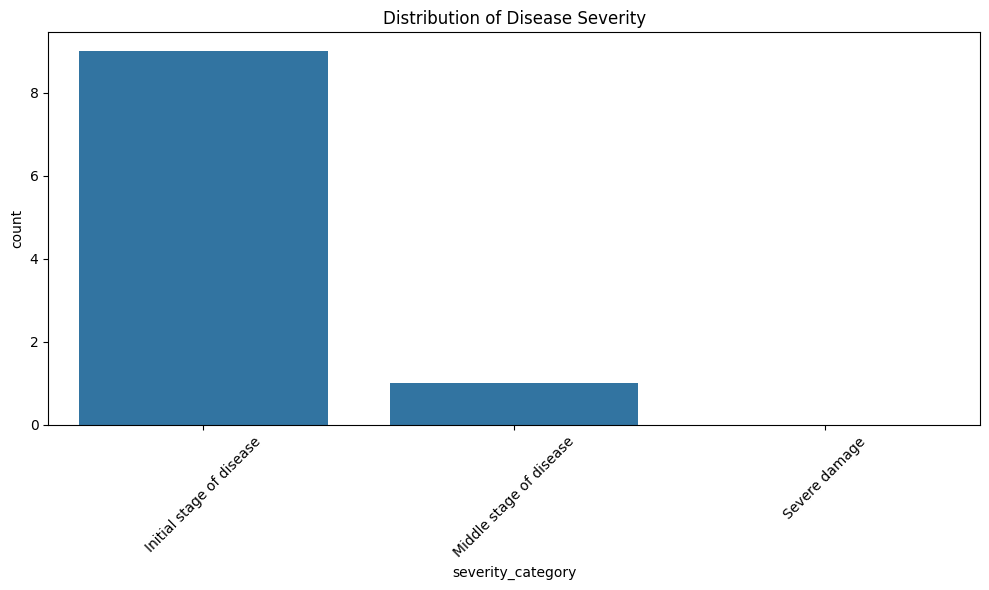

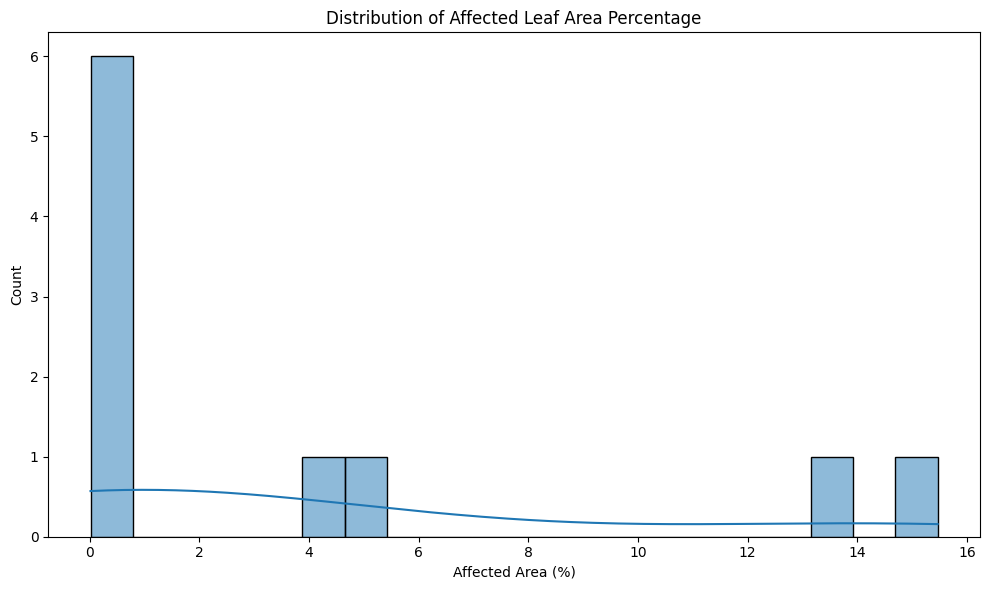

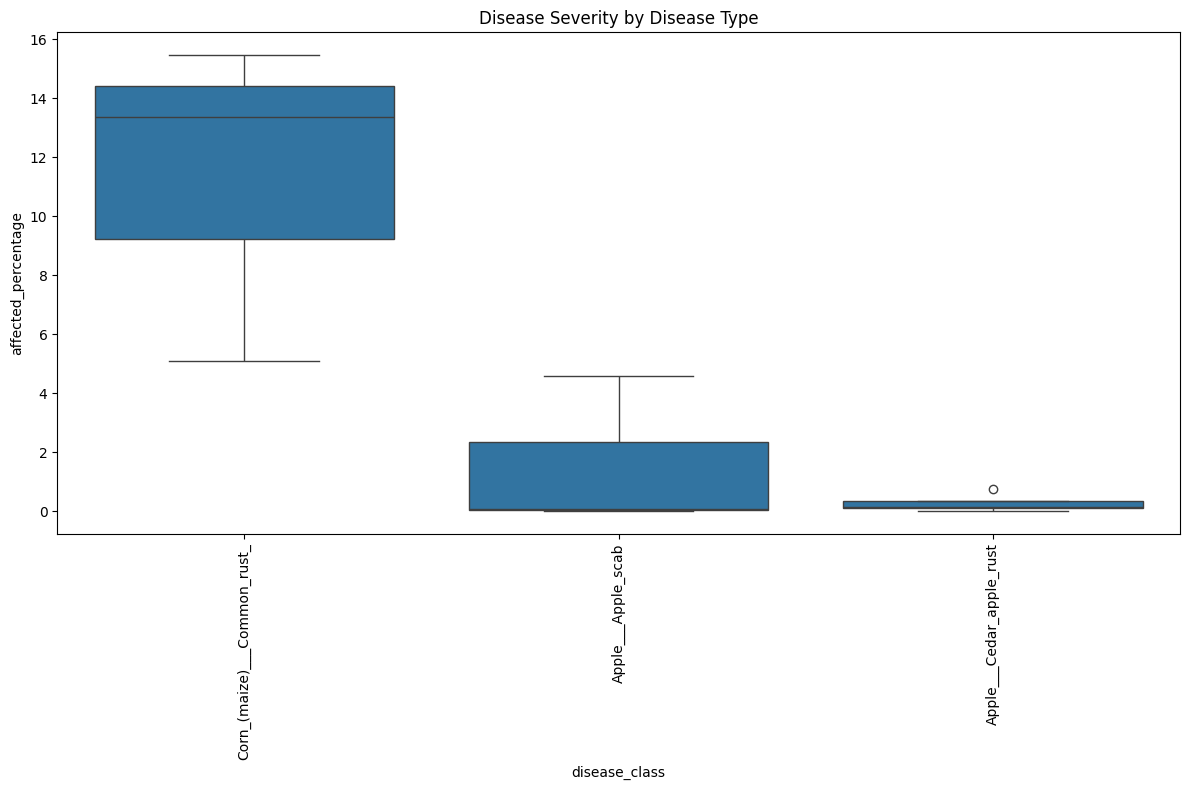

Results saved to 'combined_disease_analysis.csv'


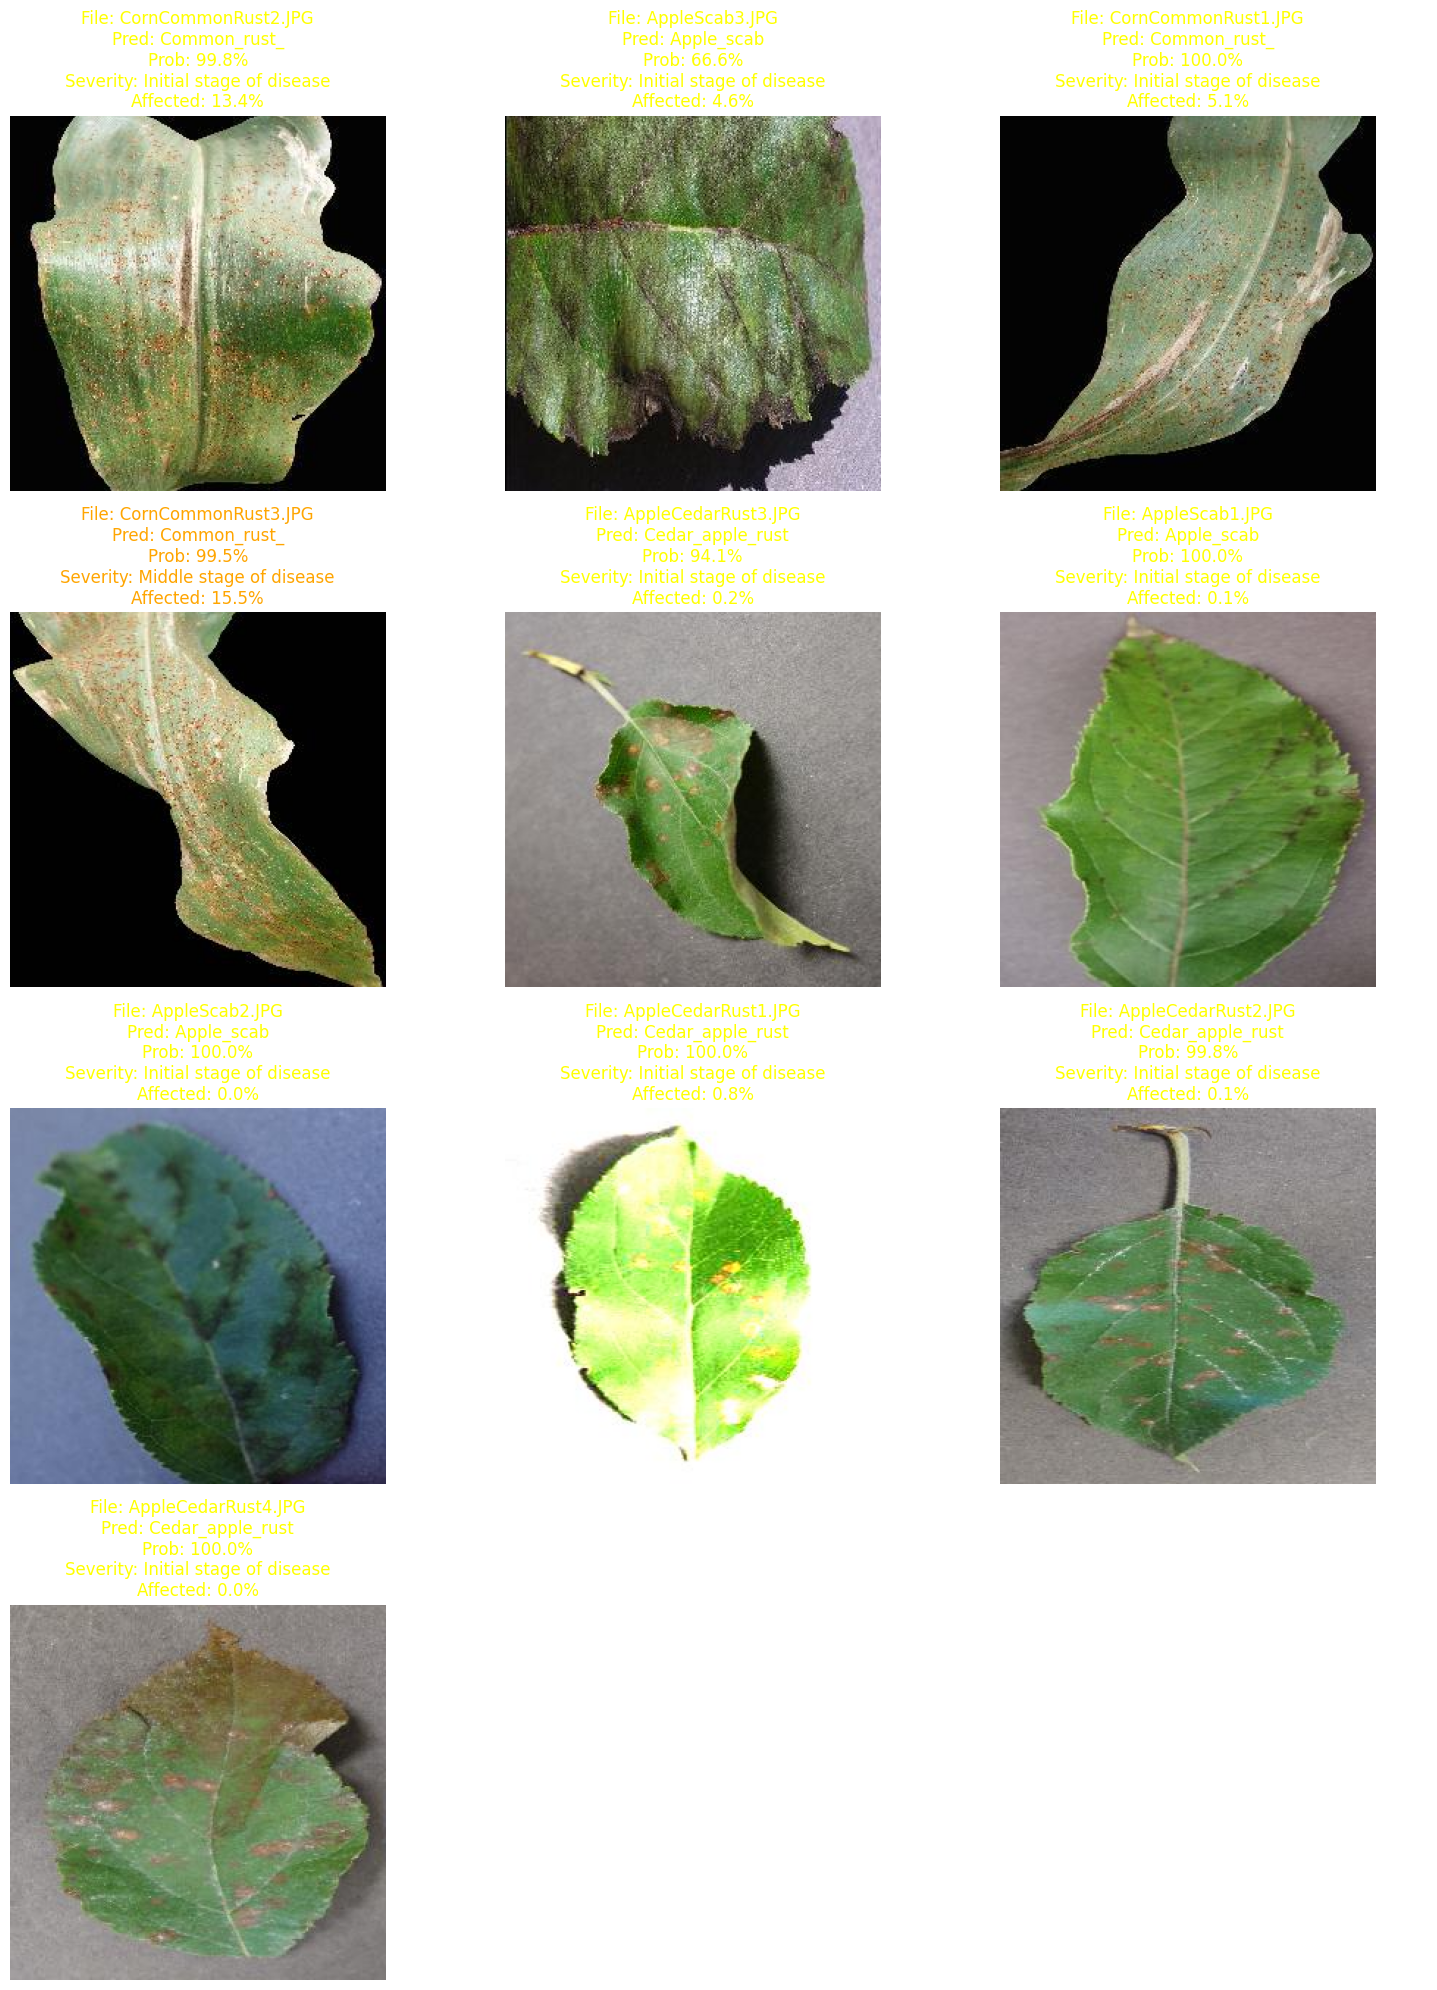

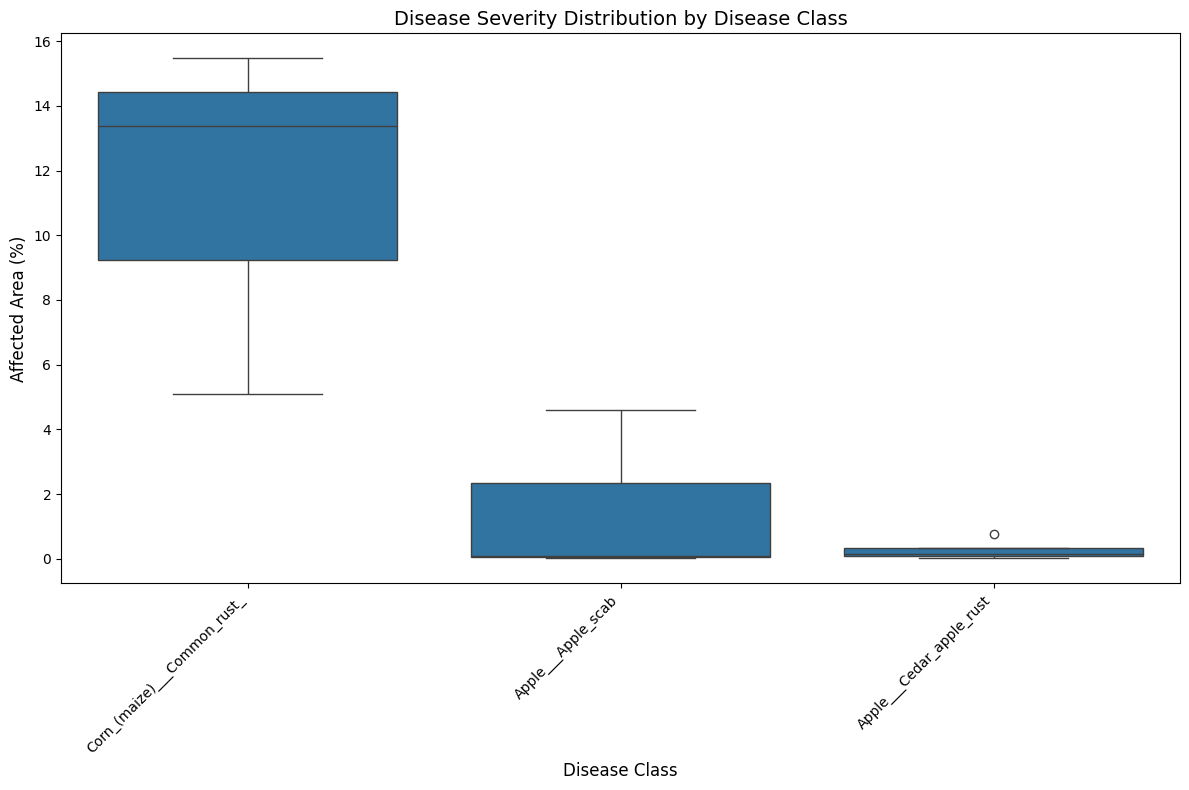

<Figure size 1200x800 with 0 Axes>

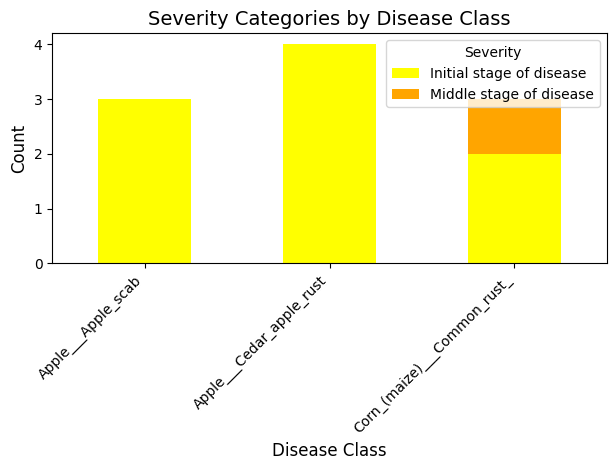

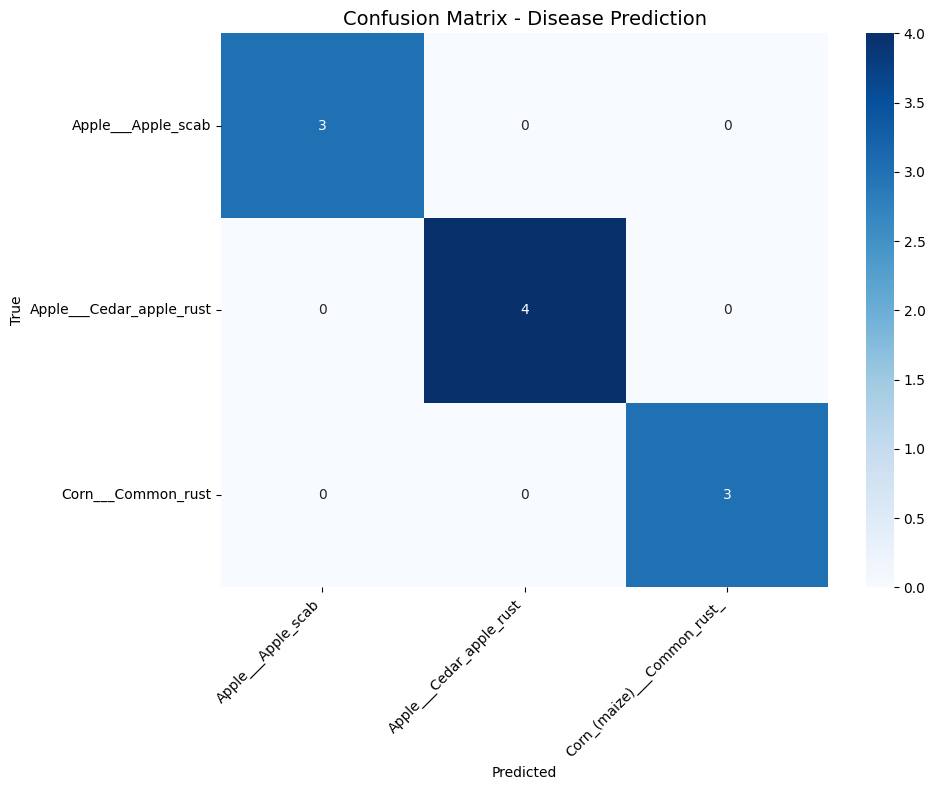


----- Disease Analysis Summary -----
Total images analyzed: 10
Disease prediction accuracy: 70.00%

Severity statistics by disease class:
                                  mean     median       min        max
predicted_class                                                       
Apple___Apple_scab            1.560011   0.083204  0.012020   4.584809
Apple___Cedar_apple_rust      0.274940   0.161757  0.014524   0.761719
Corn_(maize)___Common_rust_  11.317287  13.379516  5.105301  15.467043

Most common severity category by disease class:
predicted_class
Apple___Apple_scab             Initial stage of disease
Apple___Cedar_apple_rust       Initial stage of disease
Corn_(maize)___Common_rust_    Initial stage of disease
Name: severity_category, dtype: object


<ipython-input-9-274156926ca5>:419: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=results_df, x='severity_category', y='affected_percentage',


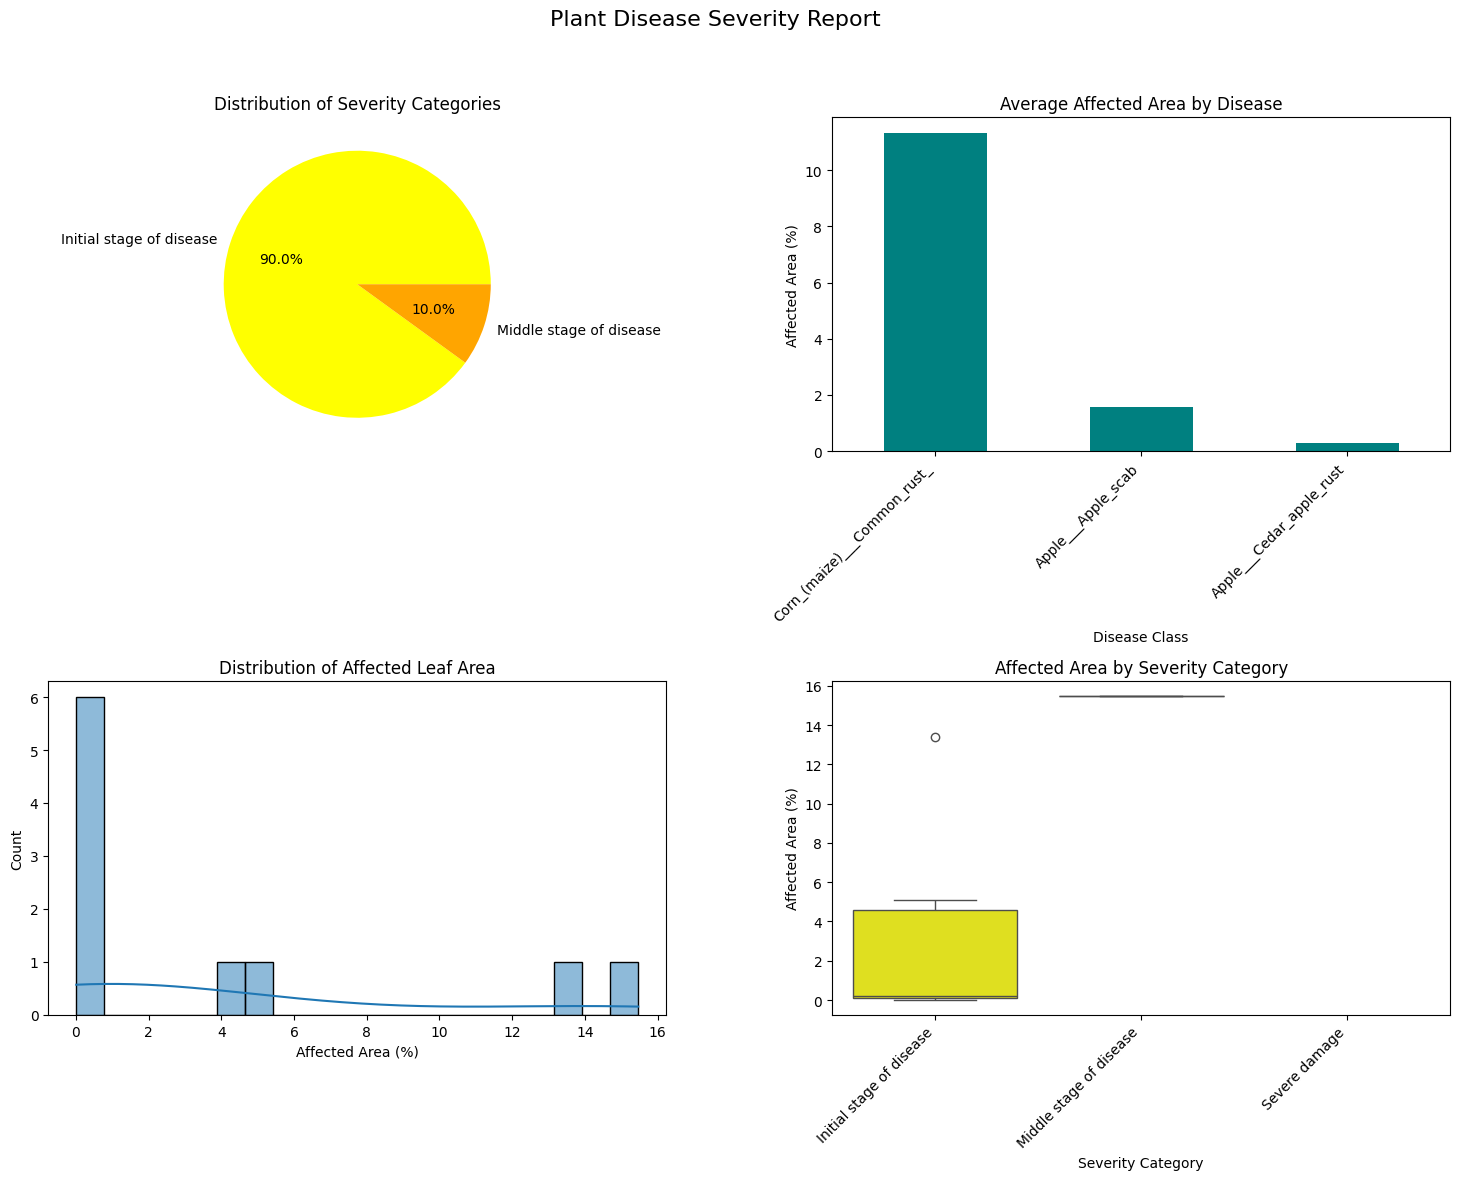

---- Plant Disease Severity Analysis ----
Total images analyzed: 10

Severity distribution:
  - Initial stage of disease: 9 images (90.0%)
  - Middle stage of disease: 1 images (10.0%)

Affected area statistics:
  - Average affected area: 3.97%
  - Median affected area: 0.48%
  - Maximum affected area: 15.47%
  - Minimum affected area: 0.01%

Analysis complete! Results summary:
--------------------------------------------------

Disease Distribution:
  - Cedar apple rust: 4 images
  - Common rust : 3 images
  - Apple scab: 3 images

Severity Distribution:
  - Initial stage of disease: 9 images
  - Middle stage of disease: 1 images

Average affected area: 3.97%

Prediction accuracy: 70.00%

Check the following files for detailed results:
  - combined_disease_analysis.csv
  - integrated_analysis_results.png
  - severity_by_disease_class.png
  - severity_categories_by_disease.png
  - disease_prediction_confusion_matrix.png
  - severity_report.png

Most severe cases:
  - CornCommonRust3.JP

In [ ]:
test_directory = "/kaggle/input/new-plant-diseases-dataset/test/test"
main(test_directory)

# **Potential Issues and Challenges:**

 1. **Hyperparameter Tuning:**
    - SVM performance sensitive to C and gamma parameters
    - Implemented grid search for CPU version
    - Used reasonable defaults for GPU version

 2. **Overfitting:**
    - Risk of model memorizing training data, especially with augmentations
    - Mitigations:
      - Used data augmentation for better generalization
      - Regularization in SVM (C parameter)
      - Separate validation set for evaluation

 3. **GPU Memory Limitations:**
    - Large datasets might not fit in GPU memory
    - Solutions implemented:
      - Batch processing for feature extraction
      - Automatic fallback to CPU when GPU fails

 4. **Feature Extraction Bottleneck:**
    - VGG16 can be slow on CPU
    - Implemented GPU acceleration where available
    - Used batch processing to manage memory

# **Conclusion**


*   SVM with VGG provided an accuracy of 98.38%

*   This time data augmentation along with hyperparameter tuning is not delayed and is applied straight away keeping in mind the big boost in accuracy it provided to the SVM with HO
*   disease severity calculation works best with a good quality image and might not be able to detect some very early stage symptoms


